In [2]:
#Project 2: Q-Learning Based Maze Solver

Learned Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]


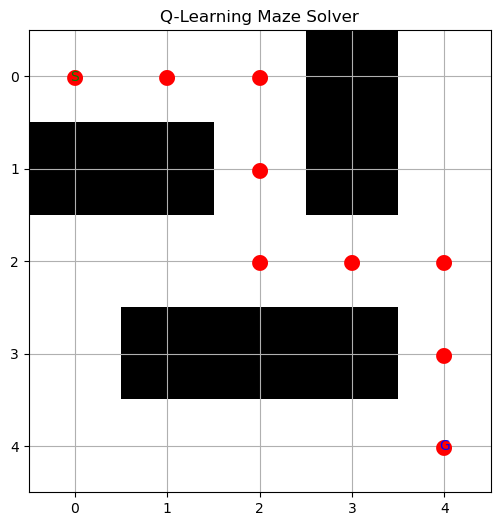

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# Step 1: Create Maze
maze = np.array([
    [0, 0, 0, 1, 0],
    [1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
])

start = (0, 0)
goal = (4, 4)

# Step 2: Define actions
actions = [
    (-1, 0),  # Up
    (1, 0),   # Down
    (0, -1),  # Left
    (0, 1)    # Right
]

# Step 3: Initialize Q-table
q_table = np.zeros((25, 4))

# Hyperparameters
alpha = 0.1
gamma = 0.9
epsilon = 0.2
episodes = 500

def state_number(position):
    return position[0] * 5 + position[1]

# Step 4: Train Agent
for episode in range(episodes):

    state = start

    for step in range(100):

        state_id = state_number(state)

        # Select action
        if np.random.random() < epsilon:
            action = np.random.randint(4)
        else:
            action = np.argmax(q_table[state_id])

        # Calculate next position
        move = actions[action]

        next_state = (
            state[0] + move[0],
            state[1] + move[1]
        )

        # Check boundaries
        if not (0 <= next_state[0] < 5 and
                0 <= next_state[1] < 5):
            next_state = state

        # Check obstacle
        if maze[next_state] == 1:
            next_state = state

        # Calculate reward
        if next_state == goal:
            reward = 100
            done = True
        elif next_state == state:
            reward = -10
            done = False
        else:
            reward = -1
            done = False

        next_id = state_number(next_state)

        # Q-learning update
        q_table[state_id, action] += alpha * (
            reward + gamma *
            np.max(q_table[next_id]) *
            (1 - done)
            - q_table[state_id, action]
        )

        state = next_state

        if done:
            break

# Step 5: Find learned path
state = start
path = [state]

for _ in range(100):

    state_id = state_number(state)
    action = np.argmax(q_table[state_id])

    move = actions[action]

    next_state = (
        state[0] + move[0],
        state[1] + move[1]
    )

    if not (0 <= next_state[0] < 5 and
            0 <= next_state[1] < 5):
        break

    if maze[next_state] == 1 or next_state == state:
        break

    state = next_state
    path.append(state)

    if state == goal:
        break

print("Learned Path:", path)

# Step 6: Visualize Maze
plt.figure(figsize=(6, 6))
plt.imshow(maze, cmap="binary")

for row, col in path:
    plt.text(col, row, "●",
             ha="center", va="center",
             color="red", fontsize=15)

plt.text(start[1], start[0], "S",
         ha="center", va="center", color="green")

plt.text(goal[1], goal[0], "G",
         ha="center", va="center", color="blue")

plt.title("Q-Learning Maze Solver")
plt.xticks(range(5))
plt.yticks(range(5))
plt.grid()
plt.show()
